# Ten years of taxi pickups, block by block and street by street

The [first notebook](nyc_taxi_dasymetric.ipynb) showed that a month of yellow-taxi pickups published by
**taxi zone** can be spread back over city blocks with **dasymetric disaggregation**: the 2013 records,
which still carried GPS coordinates, show where inside each zone taxis stop, and each later zone total
is spread the same way. Tested on July 2013, that put 5% of trips in the wrong H3 cell.

This notebook takes the method across **every month from January 2016 to December 2025**: 120 months
and 655 million trips, all spread with the same prior in a single call. Then it goes one step finer,
from H3 cells to **street segments**: each cell's estimate is shared among the streets where the 2013
taxis actually picked people up.

Keep one thing in mind while reading the maps. Every zone total is exactly what TLC published; only
where the trips fall *inside* a zone comes from 2013. So the fine-grained maps show where the trips
are, but any change over time inside them is the change of a whole zone.

*Data:* TLC yellow-taxi trip records (2013 with coordinates, 2016–2025 with zones), TLC's taxi zones,
and Manhattan's drivable streets from OpenStreetMap. `prepare.py` and `prepare_series.py` extract what
this notebook reads; see `README.md`.

In [1]:
import sys, warnings
warnings.filterwarnings("ignore", category=UserWarning)
sys.path.insert(0, "../../tutorials")          # the tutorials' map helpers

import h3
import numpy as np
import pandas as pd
import geopandas as gpd
import urbanweave as uw
from urbanweave import streets as uws

from svgmap import Map
from charts import line_chart, heat_grid, grid    # line charts, heat grids, small multiples (this folder)
from tutorial_data import show

DATA = "data"

## The inputs

- **Zone totals**: yellow-taxi pickups per taxi zone and month, 2016-01 to 2025-12.
- **Prior**: 4 million pickups with coordinates, 2 million sampled from January 2013 and 2 million
  from July 2013. The first notebook tested January alone against July. Here no month is held out,
  so both are pooled: twice the points, and a winter and a summer month.
- **Grid**: H3 resolution 10 (cells of about 0.015 km², a block or two) over the five boroughs.

In [2]:
zones = gpd.read_file(f"{DATA}/taxi_zones/taxi_zones/taxi_zones.shp")[["LocationID", "zone", "borough", "geometry"]]
jan = uw.points_from_columns(pd.read_parquet(f"{DATA}/pickups_2013-01.parquet"), lat="lat", lon="lon")
jul = uw.points_from_columns(pd.read_parquet(f"{DATA}/pickups_2013-07.parquet"), lat="lat", lon="lon")
prior = pd.concat([jan, jul], ignore_index=True)

counts = pd.read_csv(f"{DATA}/zone_counts_monthly.csv")
wide = counts.pivot_table(index="LocationID", columns="month", values="trips", aggfunc="sum", fill_value=0)
months = list(wide.columns)
no_polygon = wide.loc[~wide.index.isin(zones["LocationID"])].to_numpy().sum()
cells = uw.targets.h3_cells(zones, 10, cover="geometry")

print(f"{len(months)} months ({months[0]} to {months[-1]}), {wide.to_numpy().sum():,} trips; "
      f"{no_polygon:,} ({no_polygon / wide.to_numpy().sum():.1%}) in TLC's 'unknown' zones 264-265, which have no polygon")
print(f"{len(prior):,} prior pickups, {len(cells):,} H3 cells")

120 months (2016-01 to 2025-12), 655,494,657 trips; 8,011,387 (1.2%) in TLC's 'unknown' zones 264-265, which have no polygon
4,000,000 prior pickups, 52,395 H3 cells


## Ten years at the zone level

First, the data as published: pickups per month. The fall from 2016 to 2019 is mostly ride-hail
(Uber, Lyft) taking trips from yellow cabs, made steeper in February 2019 by the $2.50 congestion
surcharge on taxi trips south of 96th Street. Then COVID-19: pickups fell from 6.3 million in
February 2020 to 238,000 in April. The recovery stalled at about half the 2019 level, until 2025.

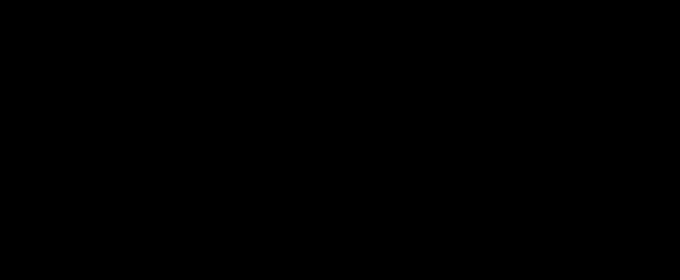

In [3]:
by_borough = (counts.merge(zones[["LocationID", "borough"]], on="LocationID", how="left")
              .fillna({"borough": "unknown zone"})
              .pivot_table(index="month", columns="borough", values="trips", aggfunc="sum", fill_value=0))
EVENTS = {"2019-02": "congestion surcharge", "2020-03": "COVID-19", "2025-01": "congestion pricing"}

line_chart(by_borough.sum(axis=1).rename("all zones").to_frame() / 1e6, "Yellow-taxi pickups per month",
           y_label="million trips", events=EVENTS, fmt=lambda v: f"{v:.0f}" if v >= 1 or v == 0 else f"{v:.1f}")

Manhattan has nine trips in ten, so a chart in trips would flatten every other borough into a line
along the bottom. Indexed to each borough's 2019 monthly average, a single axis compares them.
After congestion pricing began in January 2025, yellow pickups in Brooklyn and the Bronx tripled
within the year. (Yellow cabs also became bookable through the Uber app in 2022, which may matter
more there than in Manhattan, where most trips are hailed on the street.)

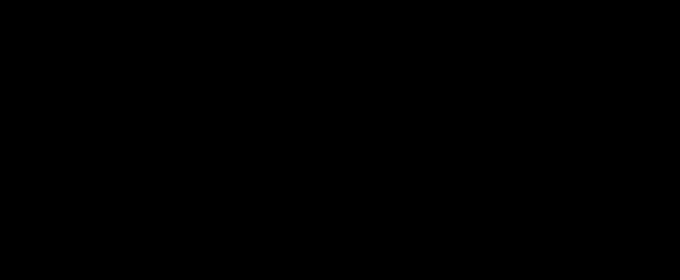

In [4]:
groups = pd.DataFrame({"Manhattan": by_borough["Manhattan"], "Queens": by_borough["Queens"],
                       "Brooklyn and Bronx": by_borough["Brooklyn"] + by_borough["Bronx"]})
base = groups.loc[[m for m in months if m.startswith("2019")]].mean()
line_chart(100 * groups / base, "Pickups per month, indexed to each borough's 2019 average (= 100)",
           y_label="2019 = 100", events=EVENTS, fmt=lambda v: f"{v:.0f}",
           note="Queens is mostly JFK and LaGuardia. Staten Island and Newark airport have a few hundred trips a month and are left out.")

## 120 months in one call

`uw.dasymetric` spreads each zone's total over the cells in proportion to the prior pickups. With
`total=` a list of columns it spreads all of them in one pass. Matching 4 million prior points to
zones and cells is nearly all of the work, and it is done once instead of 120 times.

In [5]:
zone_totals = zones.merge(wide, left_on="LocationID", right_index=True, how="left")
est = uw.dasymetric(zone_totals, cells, prior, total=months, zone_id="LocationID")

rep = uw.report_of(est)["dasymetric"]
check = pd.DataFrame({m: {"zone totals": rep["total"][m]["input"], "placed in cells": est[m].sum(),
                          "spread by area (zone without prior)": rep["total"][m]["by_area_fallback"]}
                      for m in ("2016-01", "2020-04", "2025-12")}).T
no_prior = zones.set_index("LocationID").loc[rep["zones_without_prior"]["sample"], "zone"]
print(f"{rep['pieces']:,} (cell, zone) pieces; zones without a prior pickup, spread by area:", ", ".join(no_prior.unique()))
check.style.format("{:,.0f}")

60,765 (cell, zone) pieces; zones without a prior pickup, spread by area: Broad Channel, Governor's Island/Ellis Island/Liberty Island, Great Kills Park, Oakwood


,zone totals,placed in cells,spread by area (zone without prior)
2016-01,"10,728,499","10,728,499",6
2020-04,"235,738","235,738",2
2025-12,"4,297,383","4,297,383",33


Every month places exactly its zone totals. A few zones have no 2013 pickup in the sample (Broad
Channel, Oakwood, Great Kills Park, and Governor's, Ellis and Liberty Islands), and their trips, a few
dozen a month, are spread over the zone by area. The report lists them, so nothing is filled in
silently.

The result is one column per month, about 52,000 cells × 120 months. It is saved for other uses.

In [6]:
est[["target_id"] + months].to_parquet(f"{DATA}/estimates_h3r10_monthly.parquet")
years = sorted({m[:4] for m in months})
yearly = est[["target_id", "geometry"]].copy()
yearly[years] = np.column_stack([est[[m for m in months if m.startswith(y)]].sum(axis=1) for y in years])
print(f"{len(est):,} cells; the busiest in 2016 and in 2025:")
yearly.set_index("target_id")[["2016", "2025"]].sort_values("2016", ascending=False).head(3).round(0)

52,395 cells; the busiest in 2016 and in 2025:


,2016,2025
target_id,,
8a2a100d2c17fff,1143117.0,392783.0
8a2a100d2cb7fff,681390.0,240095.0
8a2a10725a77fff,607925.0,166647.0


## Ten Manhattans

One map per year, each with the year's total pickups per cell, moved up to resolution 9 (about
0.1 km² per cell) so that ten maps fit across the page: each resolution-10 cell goes to the coarser
cell containing its centre, and the trips add up. All ten maps share one set of class bounds, so a
colour means the same number in every year.

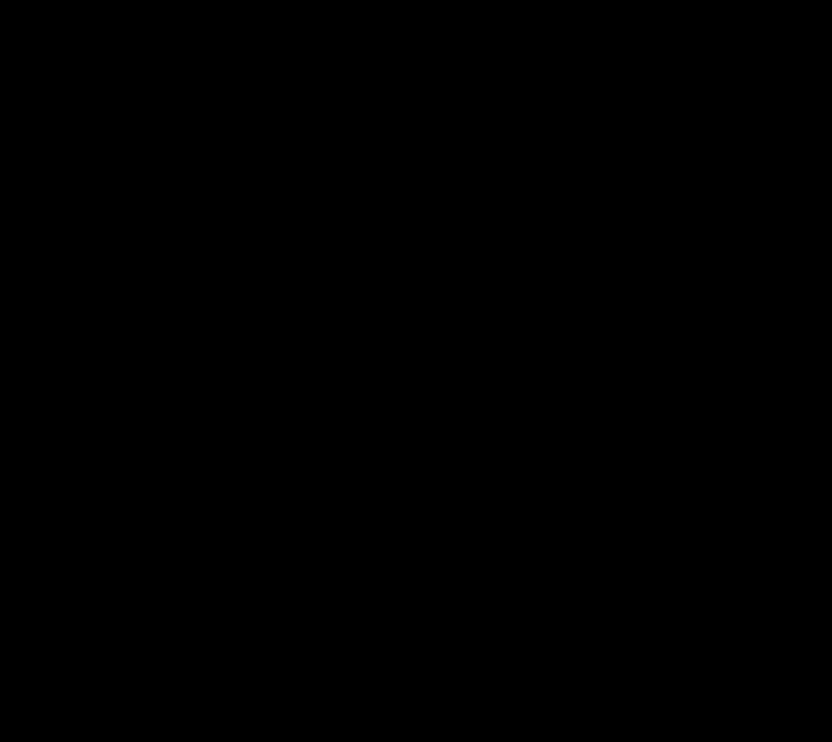

In [7]:
manhattan = zones[zones["borough"] == "Manhattan"]
zones_draw = zones.assign(geometry=zones.simplify(40))      # lighter outlines for drawing (feet, EPSG:2263)
manhattan_draw = zones_draw[zones_draw["borough"] == "Manhattan"]
cells9 = uw.targets.h3_cells(manhattan, 9, cover="geometry")
coarse = uw.aggregate(uw.match(yearly, cells9, "centroid"), None,
                      [uw.sum(y, as_=y, fill_empty=0) for y in years])
BINS_YEAR = [0, 5_000, 20_000, 50_000, 100_000, 200_000, 400_000, 2_000_000]

grid([Map(y, width=160, crs=32618)
      .fill(coarse, y, bounds=BINS_YEAR, legend="estimated pickups per cell and year", tooltip=["target_id"])
      .outline(manhattan_draw, width=0.4) for y in years], columns=5, shared_legend=True,
     title="Estimated yellow-taxi pickups per year, H3 resolution 9")

In 2016 nearly everything from the Upper East and Upper West Sides down to the Financial District is in
the top classes. Each year to 2019 lightens the map, the 2020 map is pale outside Midtown, and the
recovery since has brought back Midtown and the Upper East Side most visibly. Upper Manhattan stays in
the lowest classes throughout: yellow cabs there were always rare, and green cabs (not counted here)
serve it.

## What changed where

Inside a zone, every cell keeps its 2013 share of that zone's trips. So comparing two years cell by cell
shows nothing finer than comparing their zones, and change maps are drawn **by zone**, the level the
data actually has. Because all trips fell so much, each map shows a zone's change in **share** of the
city's yellow pickups: blue gained share, red lost it, gray held about steady (within 10%).

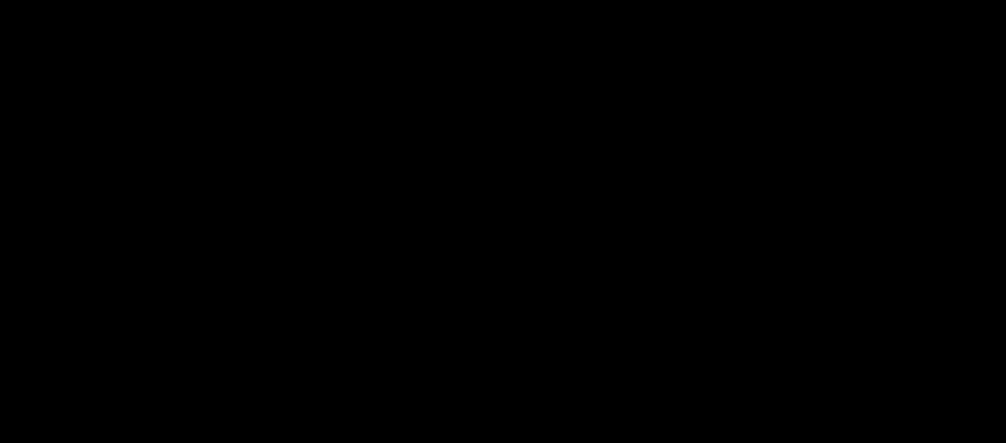

In [8]:
annual = (counts.assign(year=counts["month"].str[:4])
          .pivot_table(index="LocationID", columns="year", values="trips", aggfunc="sum", fill_value=0))
share = annual / annual.sum()
SHARE_BINS = [0, 0.5, 0.75, 0.9, 1.1, 1.33, 2, 100]

def share_change(a, b):
    z = zones_draw.merge((share[b] / share[a]).rename("ratio").reset_index(), on="LocationID")
    z.loc[annual.reindex(z["LocationID"])[a].to_numpy() < 1000, "ratio"] = np.nan   # too few trips to compare
    z["ratio"] = z["ratio"].replace([np.inf], np.nan)
    return (Map(f"{a} → {b}", width=330, crs=32618, show_legend=True)
            .fill(z, "ratio", scheme="diverging", bounds=SHARE_BINS, legend="share of city pickups, later year / earlier year",
                  tooltip=["zone", "borough"])
            .outline(zones_draw.dissolve("borough").reset_index(), width=0.6))

grid([share_change("2016", "2019"), share_change("2019", "2024"), share_change("2024", "2025")], columns=3,
     shared_legend=True, title="Where yellow-taxi trips gained and lost share (the top class is open-ended)")

- **2016 → 2019.** The neighbourhoods where ride-hail grew first lost the most share: northern Brooklyn
  (Williamsburg, Greenpoint), Alphabet City, the East Village, the Lower East Side and Stuyvesant Town.
  JFK, Harlem, East Harlem, the Upper East Side and Midtown Center gained, and so did much of the Bronx,
  Queens and southern Brooklyn, from small numbers.
- **2019 → 2024.** The airports came back best (JFK's share rose by half) along with the West
  Village, Midtown Center and Yorkville. East Harlem, Hell's Kitchen (Clinton), the Garment District and
  Battery Park City lost share.
- **2024 → 2025.** In the first year of congestion pricing, nearly every zone outside Manhattan more than
  doubled its share, and so did the Lower East Side and the East Village within Manhattan. The airports,
  Central Park and Midtown North and East lost a little.

Hatched zones had fewer than 1,000 trips in the first year of the pair.

The fine-grained estimate gives one series per block. Below are the busiest blocks (2016) of three zones.

Penn Station/Madison Sq West: busiest cell 8a2a100d2c17fff at 40.7501, -73.9915; 2016 1,143,117, 2025 392,783 pickups
Midtown East: busiest cell 8a2a100d666ffff at 40.7524, -73.9779; 2016 473,423, 2025 162,047 pickups
Lower East Side: busiest cell 8a2a1072cb5ffff at 40.7200, -73.9879; 2016 156,479, 2025 45,507 pickups


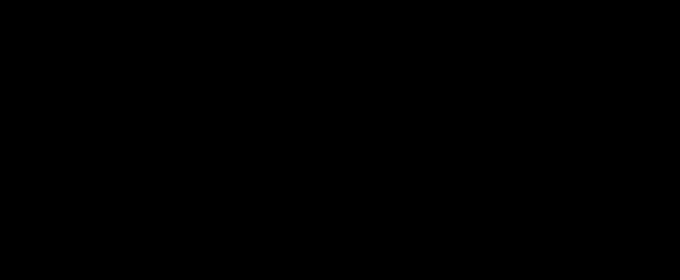

In [9]:
cell_zone = uw.match(cells, zones, "centroid", target_id="LocationID").pairs.set_index("source_id")["target_id"]
by_cell = est.set_index("target_id")
series = {}
for name in ["Penn Station/Madison Sq West", "Midtown East", "Lower East Side"]:
    lid = zones.loc[zones["zone"] == name, "LocationID"].iloc[0]
    top = yearly.set_index("target_id").loc[cell_zone.index[cell_zone == lid], "2016"].idxmax()
    lat, lon = h3.cell_to_latlng(top)
    print(f"{name}: busiest cell {top} at {lat:.4f}, {lon:.4f}; 2016 {yearly.set_index('target_id').at[top, '2016']:,.0f}, "
          f"2025 {yearly.set_index('target_id').at[top, '2025']:,.0f} pickups")
    series[name] = by_cell.loc[top, months]
line_chart(pd.DataFrame(series), "Estimated pickups per month in the busiest block of three zones", y_label="trips", events=EVENTS)

The Penn Station block, on 7th Avenue by the station's entrances, is the busiest cell in the city:
over 3,000 pickups a day in 2016. Midtown East's busiest is Grand Central's. All three fell by about
two thirds between 2016 and 2025. In 2025 the Lower East Side block grew by a third, against 13%
at Penn Station. Each series is its zone's series scaled by the block's 2013 share of that zone, so
the three curves differ only as their zones do.

## From cells to streets

Pickups happen at the curb, on a street. Manhattan's drivable streets come from OpenStreetMap as
**physical segments** (a two-way street is one segment, not two directed edges; see tutorial 6). Highways
(FDR Drive, the Henry Hudson Parkway and their ramps) are dropped: taxis don't pick people up there,
but GPS fixes from the avenues next to them would otherwise snap onto them.

A cell's estimate can be shared among the streets that cross it in two ways:

- **by length**: in proportion to each street's length inside the cell (`polygon_to_lines` measures it);
- **by the prior**: in proportion to the 2013 pickups in the cell whose nearest street, within 40 m, is
  that street (`nearest_segment`). This goes back to the same points that placed the trips in the
  cells. A cell with no snapped pickup falls back to length.

In [10]:
segments = uws.osm_streets(graphml=f"{DATA}/manhattan_drive.graphml")
segments = segments[~segments["highway"].astype(str).str.contains("motorway")].reset_index(drop=True)
mn_cells = cells[cells["target_id"].isin(uw.match(cells, manhattan, "centroid").pairs["source_id"])].reset_index(drop=True)
print(f"{len(segments):,} street segments ({segments['length_m'].sum() / 1000:,.0f} km), {len(mn_cells):,} Manhattan cells")

def snapped(points):
    # Pickups per (cell, segment): the cell a point lies in, the segment nearest to it (40 m at most).
    in_cell = uw.match(points, mn_cells, "contain").pairs[["source_id", "target_id"]]
    near = uw.match(points, segments, "nearest_segment", max_distance=40)
    pairs = in_cell.merge(near.pairs[["source_id", "target_id"]], on="source_id", suffixes=("_cell", "_segment"))
    n = pairs.groupby(["target_id_cell", "target_id_segment"]).size()
    return n.rename_axis(["cell", "segment"]).rename("w").reset_index(), len(in_cell), len(pairs)

by_length = (uw.match(mn_cells, segments, "polygon_to_lines").pairs
             .rename(columns={"source_id": "cell", "target_id": "segment", "overlap_measure": "w"})[["cell", "segment", "w"]])

def weights(snaps):
    # Each cell's share per segment: by snapped pickups, or by length where a cell has none.
    w = pd.concat([snaps, by_length[~by_length["cell"].isin(snaps["cell"])]], ignore_index=True)
    w["w"] = w["w"] / w.groupby("cell")["w"].transform("sum")
    return w

def to_streets(values, w):
    # Cell values (rows: cells, columns: anything) shared among segments by the weights w.
    v = values.reindex(w["cell"]).fillna(0).to_numpy() * w["w"].to_numpy()[:, None]
    return pd.DataFrame(v, columns=values.columns).groupby(w["segment"].to_numpy()).sum()

snap_jan, in_jan, ok_jan = snapped(jan)
snap_jul, in_jul, ok_jul = snapped(jul)
print(f"January: {ok_jan / in_jan:.1%} of the {in_jan:,} pickups in Manhattan cells lie within 40 m of a street; July: {ok_jul / in_jul:.1%}")

7,817 street segments (857 km), 3,884 Manhattan cells


January: 99.2% of the 1,851,835 pickups in Manhattan cells lie within 40 m of a street; July: 99.2%


### Does it work? July 2013 on streets

The same test as in the first notebook, carried down to the streets. July 2013's true pickups per
segment come from snapping its points. The estimate starts from July's zone totals only: cells are
rebuilt with the January prior, as in the first notebook, and shared among streets with January's
weights. A second pair of rows starts from the **true** July cells, to separate the error of the street
step from the error of the cell step.

In [11]:
july_zones = uw.aggregate(uw.match(jul, zones, "contain", target_id="LocationID"), None,
                          [uw.count(as_="trips", fill_empty=0)])[["LocationID", "trips"]]
july_cells = uw.dasymetric(zones.merge(july_zones, on="LocationID", how="left"), cells, jan,
                           total="trips", zone_id="LocationID").set_index("target_id")[["trips"]]
true_cells = uw.aggregate(uw.match(jul, mn_cells, "contain"), None, [uw.count(as_="trips", fill_empty=0)]).set_index("target_id")[["trips"]]
truth = snap_jul.groupby("segment")["w"].sum().astype(float)

jan_w = weights(snap_jan)
length_w = by_length.assign(w=by_length["w"] / by_length.groupby("cell")["w"].transform("sum"))

def compare(e):
    e = e["trips"].reindex(truth.index.union(e.index)).fillna(0)
    t = truth.reindex(e.index).fillna(0)
    busy = t >= t.quantile(0.99)
    return {"segments": int((e > 0).sum()), "trips placed": round(e.sum()),
            "share on the wrong segment": f"{(t - e).abs().sum() / t.sum() / 2:.1%}",
            "correlation with truth": round(np.corrcoef(t, e)[0, 1], 3),
            "error on the busiest 1% of segments": f"{(t - e)[busy].abs().sum() / t[busy].sum():.1%}"}

street_test = {"cells from zone totals, streets by length": to_streets(july_cells, length_w),
               "cells from zone totals, streets by the prior": to_streets(july_cells, jan_w),
               "true cells, streets by length": to_streets(true_cells, length_w),
               "true cells, streets by the prior": to_streets(true_cells, jan_w)}
pd.DataFrame({"truth": {"segments": int((truth > 0).sum()), "trips placed": int(truth.sum())},
              **{k: compare(v) for k, v in street_test.items()}}).T

,segments,trips placed,share on the wrong segment,correlation with truth,error on the busiest 1% of segments
truth,6842.0,1822652.0,NaN,NaN,NaN
"cells from zone totals, streets by length",7628,1834506,23.3%,0.857,30.1%
"cells from zone totals, streets by the prior",6841,1838692,5.7%,0.988,9.3%
"true cells, streets by length",7635,1833002,22.8%,0.865,29.3%
"true cells, streets by the prior",6983,1836993,3.8%,0.995,6.4%


Sharing a cell among its streets by length puts almost a quarter of the trips on the wrong segment,
even when the cells are exactly right. A cell 65 m across holds pieces of an avenue and of one or two
side streets, and taxis stop on the avenue. With the prior the error falls to under 6%: only about
2 points more than the cell step alone already costs. (Both the truth and the prior are GPS fixes
snapped to the nearest street, so this measures whether the street step reproduces the snapping,
not where the curb really was. In Midtown's canyons a fix can be off by tens of metres.)

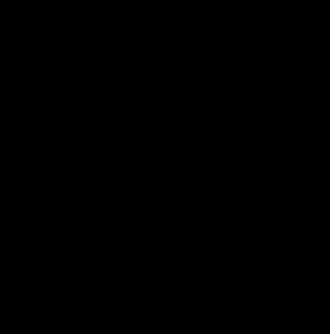

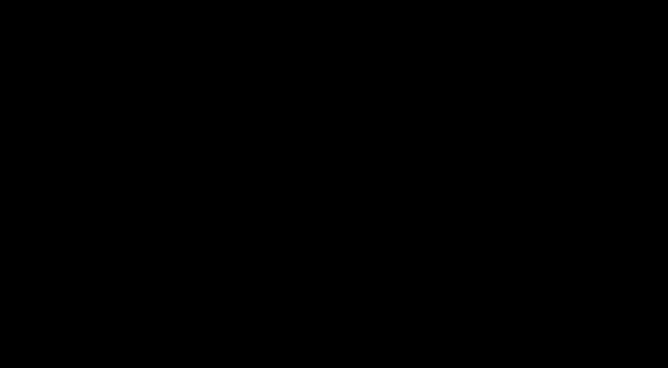

In [12]:
midtown = (-73.996, 40.748, -73.975, 40.760)          # Penn Station to Grand Central
mid = segments.cx[midtown[0]:midtown[2], midtown[1]:midtown[3]]
BINS_SEG = [0, 25, 100, 250, 500, 1000, 2500, 30000]
BINS_ERR = [-30000, -500, -150, -50, 50, 150, 500, 30000]

def street_map(values, title, error=False):
    frame = mid.merge(values.rename("trips"), left_on="target_id", right_index=True, how="left").fillna({"trips": 0})
    if error:
        frame["trips"] -= truth.reindex(frame["target_id"]).fillna(0).to_numpy()
        frame = frame.assign(size=frame["trips"].abs()).sort_values("size")
        return (Map(title, width=330, crs=32618)
                .lines(frame, "trips", scheme="diverging", bounds=BINS_ERR, width=3.2,
                       legend="estimate − truth, trips per segment", tooltip=["name"]))
    return (Map(title, width=330, crs=32618)
            .lines(frame.sort_values("trips"), "trips", bounds=BINS_SEG, width=3.2,
                   legend="pickups per segment, July 2013 sample", tooltip=["name"]))

display(street_map(truth, "Truth: snapped July 2013 pickups, Penn Station to Grand Central"))
grid([street_map(street_test["cells from zone totals, streets by the prior"]["trips"], "By the prior", error=True),
      street_map(street_test["cells from zone totals, streets by length"]["trips"], "By length", error=True)],
     columns=2, shared_legend=True, title="Error of the estimates from zone totals (red: too few, blue: too many)")

Spread by length, a cell's trips go evenly to every piece of street in it, so the cross streets get too
many (blue) and the busy avenue blocks too few (red): 7th and 8th Avenues by Penn Station, the blocks
around Grand Central. Spread by the prior, the errors are smaller and follow no pattern by street type.

### Ten years on the streets

The production run shares the 120 monthly cell estimates among segments with the pooled (January +
July) prior. Trips in Manhattan cells that contain no street at all (inside parks, on piers) cannot go
on a segment, and are counted.

In [13]:
pooled = snap_jan.merge(snap_jul, on=["cell", "segment"], how="outer", suffixes=("_jan", "_jul")).fillna(0)
pooled_w = weights(pooled.assign(w=pooled["w_jan"] + pooled["w_jul"])[["cell", "segment", "w"]])

mn_est = est.set_index("target_id").loc[mn_cells["target_id"], months]
on_streets = to_streets(mn_est, pooled_w)
off = mn_est.loc[~mn_est.index.isin(pooled_w["cell"])].to_numpy().sum()
print(f"{mn_est.to_numpy().sum():,.0f} trips in Manhattan cells; {on_streets.to_numpy().sum():,.0f} placed on "
      f"{len(on_streets):,} segments; {off:,.0f} ({off / mn_est.to_numpy().sum():.2%}) in cells with no street")

street_years = pd.DataFrame({y: on_streets[[m for m in months if m.startswith(y)]].sum(axis=1) for y in years})
street_years.rename_axis("segment").to_parquet(f"{DATA}/estimates_streets_yearly.parquet")

589,683,204 trips in Manhattan cells; 589,408,449 placed on 7,350 segments; 274,755 (0.05%) in cells with no street


Per segment, the numbers depend on how long the segment is. Divided by length, they are pickups
**per 100 m of street per day**, comparable across streets. 2025, south of 110th Street:

In [14]:
seg = segments.set_index("target_id")
days = {y: pd.Period(f"{y}-12-31").day_of_year for y in years}

def per_100m_day(y):
    frame = seg.join(street_years[y].rename("trips"), how="inner")
    frame["per_100m_day"] = frame["trips"] / days[y] / (frame["length_m"] / 100)
    return frame.reset_index()

lower = (-74.020, 40.700, -73.940, 40.800)
BINS_DENS = [0, 2, 5, 10, 20, 40, 80, 500]
frame = per_100m_day("2025").cx[lower[0]:lower[2], lower[1]:lower[3]]
frame["length_m"] = frame["length_m"].round(0)
(Map("Estimated yellow-taxi pickups per 100 m of street per day, 2025", width=560, crs=32618)
 .lines(frame.sort_values("per_100m_day"), "per_100m_day", bounds=BINS_DENS, width=1.8,
        legend="pickups per 100 m per day", tooltip=["name", "length_m"])
 .note("Segments shorter than a block carry the noisiest estimates; the hover gives each one's length."))

Pooling segments by street name gives each avenue's trajectory. The grid shows pickups per 100 m per
day for the 15 named streets with the most pickups in 2016 (counting only streets with at least 1 km
of segments), busiest first. 7th and 8th Avenues lead every year. Every street falls by about two
thirds by 2024 and recovers a little in 2025. The ranking hardly changes, because it is fixed by 2013's
pattern inside each zone plus the zones' own trends.

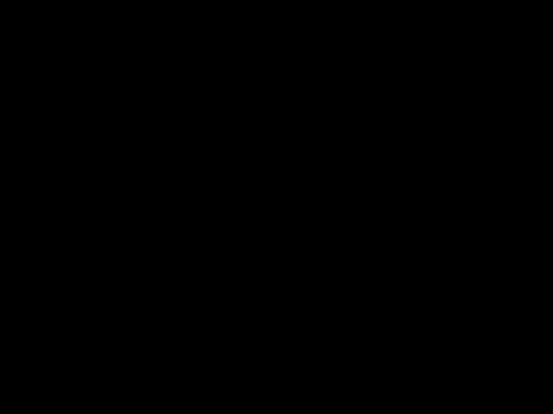

In [15]:
named = seg.join(street_years, how="inner").dropna(subset=["name"])
by_name = named.groupby("name")[years].sum()
km = named.groupby("name")["length_m"].sum() / 1000
dens = by_name.div(pd.Series(days)[years], axis=1).div(km * 10, axis=0)     # per 100 m per day
top = by_name.loc[km[km >= 1].index, "2016"].nlargest(15).index
top = dens.loc[top, "2016"].sort_values(ascending=False).index
heat_grid(dens.loc[top], "Pickups per 100 m of street per day, by named street",
          bounds=[0, 20, 40, 60, 80, 120, 160, 260], legend="pickups per 100 m per day", fmt=lambda v: f"{v:.0f}",
          note="A street's pickups over its whole length in Manhattan.")

In [16]:
dens.loc[top].round(1).to_csv("results/streets_pickups_per_100m_day.csv")
by_borough.to_csv("results/pickups_by_borough_monthly.csv")
dens.loc[top, ["2016", "2019", "2024", "2025"]].round(1)

,2016,2019,2024,2025
name,,,,
8th Avenue,253.3,164.9,74.8,83.5
7th Avenue,250.0,165.0,74.5,83.2
6th Avenue,186.3,115.7,55.2,62.5
2nd Avenue,137.2,85.8,39.2,44.5
York Avenue,124.3,82.3,44.4,50.8
Columbus Avenue,119.4,82.7,41.1,44.7
3rd Avenue,118.7,76.7,36.0,40.6
9th Avenue,115.2,72.6,33.6,37.7
Lexington Avenue,110.0,77.3,37.6,41.8


## Where did the yellow trips go?

Ride-hail companies report every trip to TLC as well, by pickup zone and never with coordinates.
`prepare_fhv.py` counts them per zone and month. From February 2019 the records name the company
(Uber, Lyft, Via, Juno). Before that they name only the dispatching base, and each base is given the
company it dispatches for in the later records. Juno's records before 2019 carry no zone, so Juno counts
only from 2019; it was about 5% of app trips in 2018.

First the totals, checked against TLC's own monthly industry report:

In [17]:
fhv = pd.read_csv(f"{DATA}/fhv_zone_counts_monthly.csv")
apps = fhv.pivot_table(index="month", columns="company", values="trips", aggfunc="sum", fill_value=0).reindex(months).fillna(0)
yellow_total = by_borough.sum(axis=1)

report = pd.read_csv(f"{DATA}/tlc_monthly_report.csv", thousands=",")
report = report.pivot_table(index="Month/Year", columns="License Class", values="Trips Per Day")
days_in = pd.Series({m: pd.Period(m).days_in_month for m in months})
check = pd.DataFrame({"yellow, these counts": yellow_total, "yellow, TLC report": report["Yellow"].reindex(months) * days_in,
                      "apps, these counts": apps.sum(axis=1),
                      "apps, TLC report": report["FHV - High Volume"].reindex(months) * days_in})
check.loc[["2016-06", "2018-06", "2019-06", "2020-04", "2023-06", "2025-06"]].style.format("{:,.0f}")

,"yellow, these counts","yellow, TLC report","apps, these counts","apps, TLC report"
2016-06,"11,131,645","11,137,710","7,146,519","7,266,990"
2018-06,"8,714,143","8,710,860","18,778,564","18,792,690"
2019-06,"6,971,026","6,940,050","21,001,990","21,001,080"
2020-04,"237,941","237,930","4,312,909","4,312,860"
2023-06,"3,307,193","3,292,980","19,366,619","19,366,470"
2025-06,"4,322,940","4,269,600","19,868,009","19,867,950"


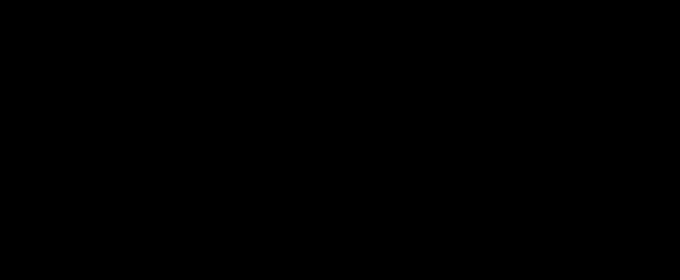

In [18]:
line_chart(pd.DataFrame({"Yellow": yellow_total, "Uber": apps["Uber"], "Lyft": apps["Lyft"]}) / 1e6,
           "Pickups per month: yellow cabs and the two largest ride-hail apps", y_label="million trips",
           events=EVENTS, fmt=lambda v: f"{v:.0f}",
           note="Uber and Lyft from their TLC trip records; Via and Juno (together under 10% of app trips) not drawn.")

The two sources agree with TLC's report to within 1% in every month checked. Uber passed yellow cabs
in July 2017, and by 2019 Uber alone made more than twice as many trips. The total grew: yellow plus
apps went from 16 million trips a month in January 2016 to 28 million in mid-2019. Between 2016 and 2019
yellow lost 47 million trips a year while the apps gained 165 million. So the apps did not only take
yellow's trips; they carried far more trips than yellow ever had.

COVID-19 then hit yellow far harder. In April 2020 the apps kept 20% of their February trips and
yellow kept 4%. In 2024 the apps were back to 94% of their 2019 volume, and yellow to 49%.

Where yellow held on is clearer as a share: yellow's pickups as a percentage of yellow and app pickups
together, in Manhattan, at the airports (JFK, LaGuardia, Newark) and in the rest of the city.

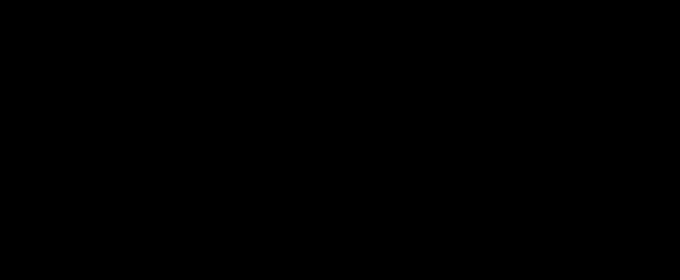

In [19]:
AIRPORTS = [1, 132, 138]
area = zones.set_index("LocationID")["borough"].map(lambda b: "Manhattan" if b == "Manhattan" else "rest of the city")
area[AIRPORTS] = "airports"

def by_area(frame):
    f = frame[frame["LocationID"].isin(area.index)]
    return f.assign(area=area.reindex(f["LocationID"]).to_numpy()).pivot_table(
        index="month", columns="area", values="trips", aggfunc="sum", fill_value=0).reindex(months)

y_area, a_area = by_area(counts), by_area(fhv.dropna(subset=["LocationID"]))
yellow_share = 100 * y_area / (y_area + a_area)
line_chart(yellow_share[["Manhattan", "airports", "rest of the city"]],
           "Yellow cabs' share of yellow + ride-hail pickups", y_label="% of pickups", events=EVENTS,
           fmt=lambda v: f"{v:.0f}%")

By zone, three years: before the apps took over (2016), just before COVID (2019) and the latest (2025).

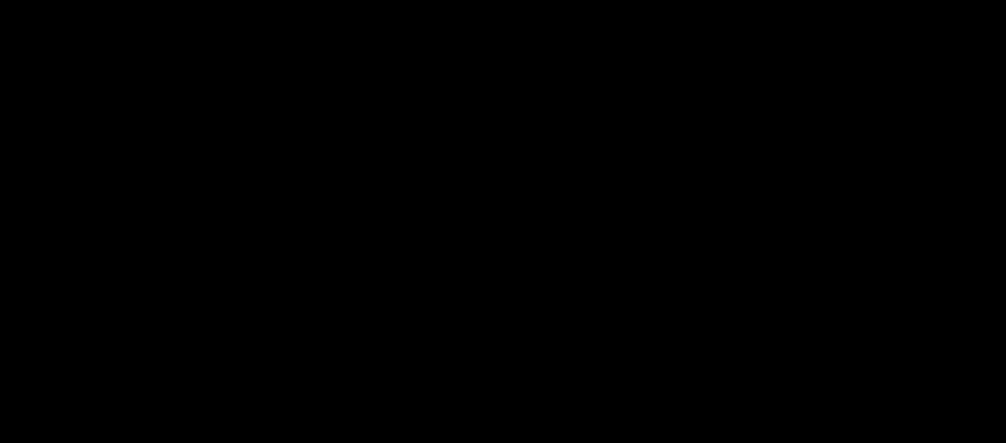

In [20]:
def zone_year(frame, y):
    f = frame[frame["month"].str.startswith(y)].dropna(subset=["LocationID"])
    return f.groupby(f["LocationID"].astype(int))["trips"].sum()

def share_map(y):
    yl, ap = zone_year(counts, y), zone_year(fhv, y)
    both = yl.add(ap, fill_value=0)
    z = zones_draw.merge((100 * yl.reindex(both.index).fillna(0) / both).rename("yellow %").reset_index()
                         .rename(columns={"index": "LocationID"}), on="LocationID", how="left")
    z.loc[both.reindex(z["LocationID"]).fillna(0).to_numpy() < 10_000, "yellow %"] = np.nan   # too few trips
    return (Map(y, width=330, crs=32618)
            .fill(z, "yellow %", bounds=[0, 2, 5, 10, 20, 35, 50, 100], legend="yellow cabs' share of pickups, %",
                  tooltip=["zone", "borough"])
            .outline(zones_draw.dissolve("borough").reset_index(), width=0.6))

grid([share_map(y) for y in ("2016", "2019", "2025")], columns=3, shared_legend=True,
     title="Yellow cabs' share of yellow + ride-hail pickups, by zone")

### Did yellow lose most where the apps grew most?

If the apps simply took yellow's passengers, the zones where app trips grew most between 2016 and 2019
should be the zones where yellow trips fell most. Split the zones into three equal groups by how much
app pickups grew (zones with at least 100,000 yellow and app trips in 2016):

In [21]:
z16 = pd.DataFrame({"yellow": zone_year(counts, "2016"), "apps": zone_year(fhv, "2016")}).fillna(0)
z19 = pd.DataFrame({"yellow": zone_year(counts, "2019"), "apps": zone_year(fhv, "2019")}).fillna(0)
zz = z16.add_suffix(" 2016").join(z19.add_suffix(" 2019"), how="inner")
zz = zz[(zz["yellow 2016"] + zz["apps 2016"] >= 100_000) & (zz["apps 2016"] > 0)]
zz["app growth"] = zz["apps 2019"] / zz["apps 2016"]
zz["group"] = pd.qcut(zz["app growth"], 3, labels=["apps grew least", "middle", "apps grew most"])
g = zz.groupby("group", observed=True)[["yellow 2016", "yellow 2019", "apps 2016", "apps 2019"]].sum()
table = pd.DataFrame({
    "zones": zz.groupby("group", observed=True).size(),
    "app trips, 2019 / 2016": g["apps 2019"] / g["apps 2016"],
    "yellow trips, 2019 / 2016": g["yellow 2019"] / g["yellow 2016"],
    "all trips, 2019 / 2016": (g["yellow 2019"] + g["apps 2019"]) / (g["yellow 2016"] + g["apps 2016"]),
    "yellow share 2016": g["yellow 2016"] / (g["yellow 2016"] + g["apps 2016"]),
    "yellow share 2019": g["yellow 2019"] / (g["yellow 2019"] + g["apps 2019"]),
})
r = np.corrcoef(np.log(zz["app growth"]), np.log(zz["yellow 2019"] / zz["yellow 2016"]))[0, 1]
print(f"{len(zz)} zones; correlation across zones of log app growth and log yellow change: {r:.2f}")
table.style.format({"zones": "{:d}", "app trips, 2019 / 2016": "{:.2f}", "yellow trips, 2019 / 2016": "{:.2f}",
                    "all trips, 2019 / 2016": "{:.2f}", "yellow share 2016": "{:.0%}", "yellow share 2019": "{:.0%}"})

155 zones; correlation across zones of log app growth and log yellow change: 0.30


,zones,"app trips, 2019 / 2016","yellow trips, 2019 / 2016","all trips, 2019 / 2016",yellow share 2016,yellow share 2019
group,,,,,,
apps grew least,52,1.93,0.64,1.03,70%,43%
middle,51,3.13,0.69,2.29,34%,10%
apps grew most,52,5.66,0.58,4.51,23%,3%


No. Yellow lost about the same share of its trips in every group, 31% to 42%, whether app trips doubled
or grew almost sixfold. Across zones, the correlation between app growth and yellow's change is
slightly *positive* (0.30). What differs between the groups is the total:

- Where the apps grew least, yellow had 70% of pickups in 2016 (Manhattan's core and the airports), and
  the total barely moved (+3%). There the apps took yellow's passengers, nearly trip for trip.
- Where the apps grew most, yellow had only 23% of pickups, and the total grew 4.5 times. Those are
  mostly trips that yellow cabs never carried, in neighbourhoods they rarely served.

So the drop in yellow trips is two stories. In Manhattan and at the airports the apps replaced yellow
cabs. In the rest of the city yellow was already marginal, and the apps grew a much larger market of
their own. COVID-19 then cut yellow's share in half again, and it never fully recovered.

2025 is the first year yellow's share rose. In Manhattan it went from 28% in 2024 to 32%; outside
Manhattan and the airports it went from 1% to 2–3%, where the Brooklyn and Bronx trips tripled.
The timing matches congestion pricing, whose per-trip charge in the zone is $0.75 for a taxi trip
against $1.50 for an app trip. Yellow cabs have also been bookable in the Uber app since 2022. The data
here cannot separate the two.

In [22]:
pd.DataFrame({"yellow": yellow_total, **{c: apps[c] for c in apps.columns}}).to_csv("results/yellow_and_apps_monthly.csv")
yellow_share.round(2).to_csv("results/yellow_share_by_area_monthly.csv")

## What the estimates can and cannot say

- **Totals are data, placement is model.** Every zone's monthly total is what TLC published. Placement
  inside a zone, down to the cell and the street, is the 2013 pattern. A new hotel, a closed station,
  a redesigned avenue or a new bike lane inside a zone is invisible, and so is any shift of trips
  between blocks of the same zone. Change over time is real only at the zone level.
- **Thin priors outside Manhattan.** In 2013 yellow cabs rarely picked up in the outer boroughs (green
  cabs began that August), so Brooklyn's and the Bronx's cells rest on a few points each. Their
  2025 growth is real at the zone level, but its placement inside those zones rests on very little.
- **Streets inherit GPS error.** 2013 fixes in Midtown can be tens of metres off, so a pickup on an
  avenue can snap to a cross street, and the street test above measures agreement with that snapping.
  Streets left out of OSM's drivable network (or motorways, removed here) receive nothing.
- **A different prior is a single change.** A prior from another year, or one built from points of
  interest, is the same `uw.dasymetric` call with a different layer: `compare_priors.py` compares
  several. With a prior per period (if one existed), the within-zone pattern could change over time too.